# Introduction to Neural Networks: ReneWind

##Problem Statement

###Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S. Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

### Dataset Descrition
* Total features: 40 input features
* Feature names: V1 to V40
* Target variable: Target (Binary classification)
V1 - V40: These are anonymized numerical features representing sensor measurements / operational parameters.

Since the dataset is preprocessed or anonymized, the exact meaning of each variable is not available.

“1” in the target variable should be considered as “failure” and “0” represents “No failure”.

##Objective

The objective of this project is to develop and tune classification models to accurately predict generator failures using sensor data. The goal is to reduce overall maintenance costs by identifying potential failures early, thereby minimizing expensive replacements and improving operational efficiency.

### Let us start by importing the required libraries

In [ ]:
# Library for data manipulation and analysis.
import pandas as pd
# Fundamental package for scientific computing.
import numpy as np
#splitting datasets into training and testing sets.
from sklearn.model_selection import train_test_split
#Imports tools for data preprocessing including label encoding, one-hot encoding, and standard scaling
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,StandardScaler
#Imports a class for imputing missing values in datasets.
from sklearn.impute import SimpleImputer
#Imports the Matplotlib library for creating visualizations.
import matplotlib.pyplot as plt
# Imports the Seaborn library for statistical data visualization.
import seaborn as sns
# Time related functions.
import time
#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report


#Imports the tensorflow,keras and layers.
import tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dense, Input, Dropout,BatchNormalization
from tensorflow.keras import backend

# to suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(812)

# If using TensorFlow, this will make GPU ops as deterministic as possible,
# but it will affect the overall performance, so be mindful of that.
tf.config.experimental.enable_op_determinism()

### Understanding the structure of the data

In [ ]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load the dataset from CSV file
train_data = pd.read_csv("/content/drive/MyDrive/PGP AIML Colab Notebooks/Train.csv")
test_data = pd.read_csv("/content/drive/MyDrive/PGP AIML Colab Notebooks/Test.csv")

In [ ]:
# Create a working copy of the data for analysis
df = train_data.copy()

In [ ]:
# Create a working copy of the test data for analysis
df_test=test_data.copy()

###View the first and last 5 rows of the dataset.

In [ ]:
# Display the first 5 rows of the dataset to inspect data
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,...,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,...,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,...,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,...,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,...,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0


In [ ]:
# Display the last 5 rows of the dataset to inspect data
df.tail()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
19995,-2.071318,-1.088279,-0.796174,-3.011720,-2.287540,2.807310,0.481428,0.105171,-0.586599,-2.899398,...,-8.273996,5.745013,0.589014,-0.649988,-3.043174,2.216461,0.608723,0.178193,2.927755,1
19996,2.890264,2.483069,5.643919,0.937053,-1.380870,0.412051,-1.593386,-5.762498,2.150096,0.272302,...,-4.159092,1.181466,-0.742412,5.368979,-0.693028,-1.668971,3.659954,0.819863,-1.987265,0
19997,-3.896979,-3.942407,-0.351364,-2.417462,1.107546,-1.527623,-3.519882,2.054792,-0.233996,-0.357687,...,7.112162,1.476080,-3.953710,1.855555,5.029209,2.082588,-6.409304,1.477138,-0.874148,0
19998,-3.187322,-10.051662,5.695955,-4.370053,-5.354758,-1.873044,-3.947210,0.679420,-2.389254,5.456756,...,0.402812,3.163661,3.752095,8.529894,8.450626,0.203958,-7.129918,4.249394,-6.112267,0
19999,-2.686903,1.961187,6.137088,2.600133,2.657241,-4.290882,-2.344267,0.974004,-1.027462,0.497421,...,6.620811,-1.988786,-1.348901,3.951801,5.449706,-0.455411,-2.202056,1.678229,-1.974413,0


In [ ]:
# Display the first 5 rows of the dataset to inspect data
df_test.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-0.613489,-3.819640,2.202302,1.300420,-1.184929,-4.495964,-1.835817,4.722989,1.206140,-0.341909,...,2.291204,-5.411388,0.870073,0.574479,4.157191,1.428093,-10.511342,0.454664,-1.448363,0
1,0.389608,-0.512341,0.527053,-2.576776,-1.016766,2.235112,-0.441301,-4.405744,-0.332869,1.966794,...,-2.474936,2.493582,0.315165,2.059288,0.683859,-0.485452,5.128350,1.720744,-1.488235,0
2,-0.874861,-0.640632,4.084202,-1.590454,0.525855,-1.957592,-0.695367,1.347309,-1.732348,0.466500,...,-1.318888,-2.997464,0.459664,0.619774,5.631504,1.323512,-1.752154,1.808302,1.675748,0
3,0.238384,1.458607,4.014528,2.534478,1.196987,-3.117330,-0.924035,0.269493,1.322436,0.702345,...,3.517918,-3.074085,-0.284220,0.954576,3.029331,-1.367198,-3.412140,0.906000,-2.450889,0
4,5.828225,2.768260,-1.234530,2.809264,-1.641648,-1.406698,0.568643,0.965043,1.918379,-2.774855,...,1.773841,-1.501573,-2.226702,4.776830,-6.559698,-0.805551,-0.276007,-3.858207,-0.537694,0


In [ ]:
# Display the last 5 rows of the dataset to inspect data
df_test.tail()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
4995,-5.120451,1.634804,1.251259,4.035944,3.291204,-2.932230,-1.328662,1.754066,-2.984586,1.248633,...,9.979118,0.063438,0.217281,3.036388,2.109323,-0.557433,1.938718,0.512674,-2.694194,0
4996,-5.172498,1.171653,1.579105,1.219922,2.529627,-0.668648,-2.618321,-2.000545,0.633791,-0.578938,...,4.423900,2.603811,-2.152170,0.917401,2.156586,0.466963,0.470120,2.196756,-2.376515,0
4997,-1.114136,-0.403576,-1.764875,-5.879475,3.571558,3.710802,-2.482952,-0.307614,-0.921945,-2.999141,...,3.791778,7.481506,-10.061396,-0.387166,1.848509,1.818248,-1.245633,-1.260876,7.474682,0
4998,-1.703241,0.614650,6.220503,-0.104132,0.955916,-3.278706,-1.633855,-0.103936,1.388152,-1.065622,...,-4.100352,-5.949325,0.550372,-1.573640,6.823936,2.139307,-4.036164,3.436051,0.579249,0
4999,-0.603701,0.959550,-0.720995,8.229574,-1.815610,-2.275547,-2.574524,-1.041479,4.129645,-2.731288,...,2.369776,-1.062408,0.790772,4.951955,-7.440825,-0.069506,-0.918083,-2.291154,-5.362891,0


### Rows and Columns in data set

In [ ]:
# Check the shape of the dataset (rows, columns)
df.shape

(20000, 41)

#### Observations:
There are 20000 rows and 41 columns

In [ ]:
# Check the shape of the test dataset (rows, columns)
df_test.shape

(5000, 41)

#### Observations:
There are 5000 rows and 41 columns in test data

### Check the data types of the columns for the dataset.

In [ ]:
# Check the data types of each column in the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

#### Observations:
Target is integer and all the features are of float type.

In [ ]:
# Check the data types of each column in the dataset
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

#### Observations:
Target is integer and all the features are of float type.

### Checking for missing values

In [ ]:
# Check for missing values in each column
df.isnull().sum()

,0
V1,18
V2,18
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


#### Observations:
Most features have complete data except V1 and V2, which contain 18 missing values each.

In [ ]:
# Check for missing values in each column
df_test.isnull().sum()

,0
V1,5
V2,6
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


#### Observations:
Most features have complete data except V1 and V2 i.e V1 has 5 missing values and V2 has 5 missing values.

### Check the duplicate values

In [ ]:
# Check for duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

#### Observations:
There are no duplicates in the given data set

### Target distribution


In [ ]:
# Target distribution
df['Target'].value_counts(normalize=True)

,proportion
Target,
0,0.9445
1,0.0555


##Observations

`Failure` percentage is 0.0555 in the given dataset which is very low when compared to  `No failure`

### Statistical Summary of the data

In [ ]:
# Get statistical summary for all columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,19982.0,-0.271996,3.441625,-11.876451,-2.737146,-0.747917,1.840112,15.493002
V2,19982.0,0.440430,3.150784,-12.319951,-1.640674,0.471536,2.543967,13.089269
V3,20000.0,2.484699,3.388963,-10.708139,0.206860,2.255786,4.566165,17.090919
V4,20000.0,-0.083152,3.431595,-15.082052,-2.347660,-0.135241,2.130615,13.236381
V5,20000.0,-0.053752,2.104801,-8.603361,-1.535607,-0.101952,1.340480,8.133797
V6,20000.0,-0.995443,2.040970,-10.227147,-2.347238,-1.000515,0.380330,6.975847
V7,20000.0,-0.879325,1.761626,-7.949681,-2.030926,-0.917179,0.223695,8.006091
V8,20000.0,-0.548195,3.295756,-15.657561,-2.642665,-0.389085,1.722965,11.679495
V9,20000.0,-0.016808,2.160568,-8.596313,-1.494973,-0.067597,1.409203,8.137580
V10,20000.0,-0.012998,2.193201,-9.853957,-1.411212,0.100973,1.477045,8.108472


#### Observations:
The features have different ranges and moderate spread, with some extreme values indicating possible outliers.


## Exploratory Data Analysis (EDA) Summary

In [ ]:
# Define a function to plot histogram and boxplot together for a feature
def histogram_boxplot(data, feature, figsize=(10,8), kde=True, bins=None):
    """
    Boxplot and histogram combined for a feature
    data: dataframe
    feature: column name
    figsize: size of figure
    kde: show density curve
    bins: number of bins for histogram
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    if bins:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins)
    else:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2)

### Univarient Analysis

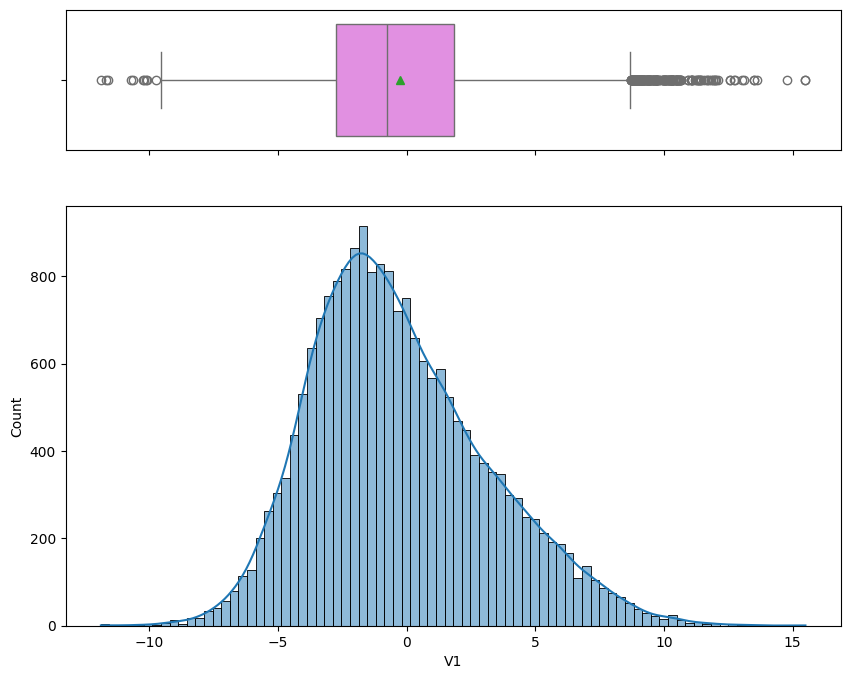

In [ ]:
# Plot histogram and boxplot for V1 feature
histogram_boxplot(df, "V1")

#### Observations
V1 shows a slightly right-skewed distribution with most values concentrated around the center and several extreme outliers on both ends, especially on the positive side.

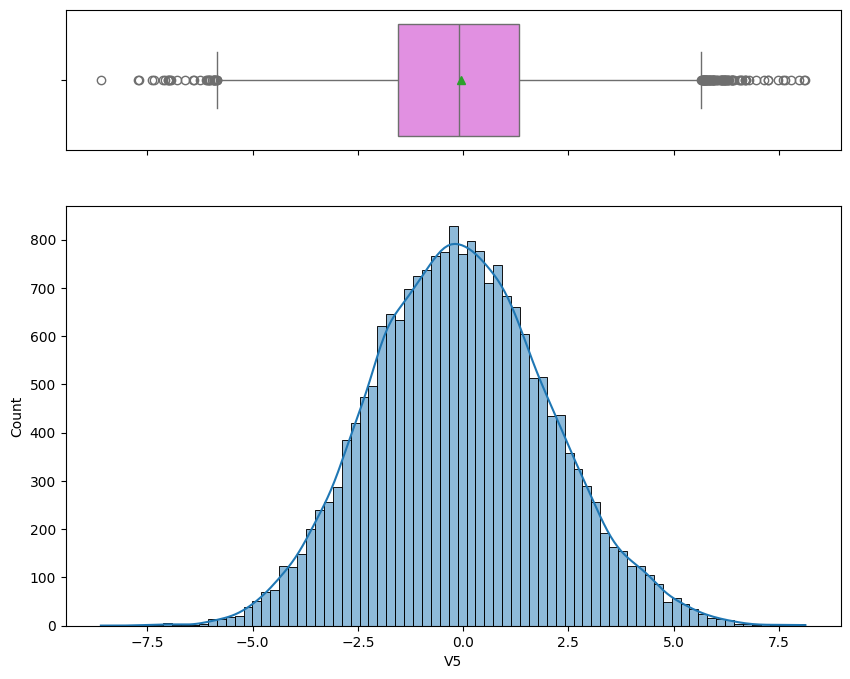

In [ ]:
# Plot histogram and boxplot for V5 feature
histogram_boxplot(df, "V5")

#### Observations
V5 appears approximately normally distributed around 0 with moderate spread and a few extreme outliers on both tails.

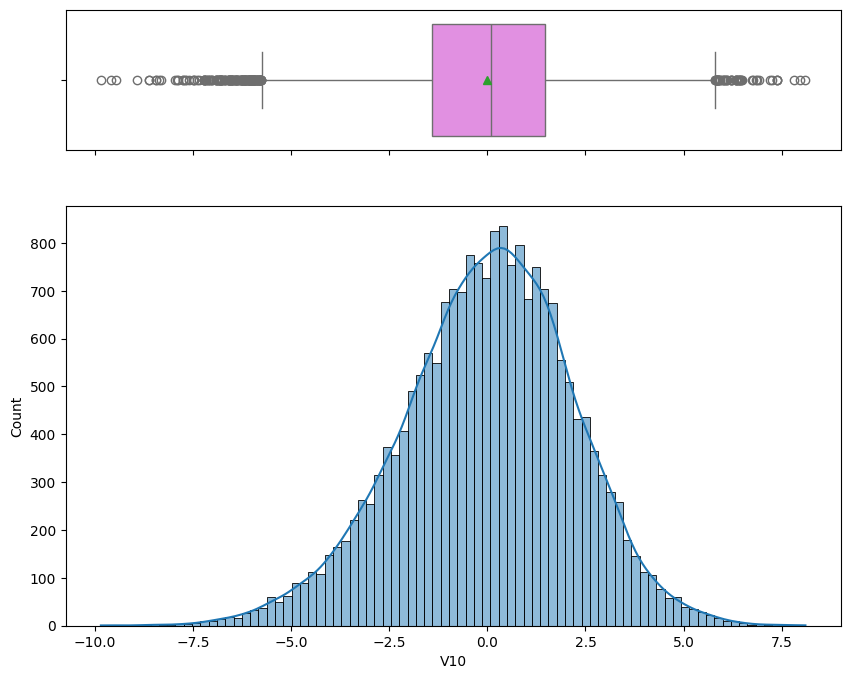

In [ ]:
# Plot histogram and boxplot for V10 feature
histogram_boxplot(df, "V10")

#### Observations
V10 appears approximately normally distributed around 0 with moderate spread and a few outliers on both tails, slightly more on the negative side.

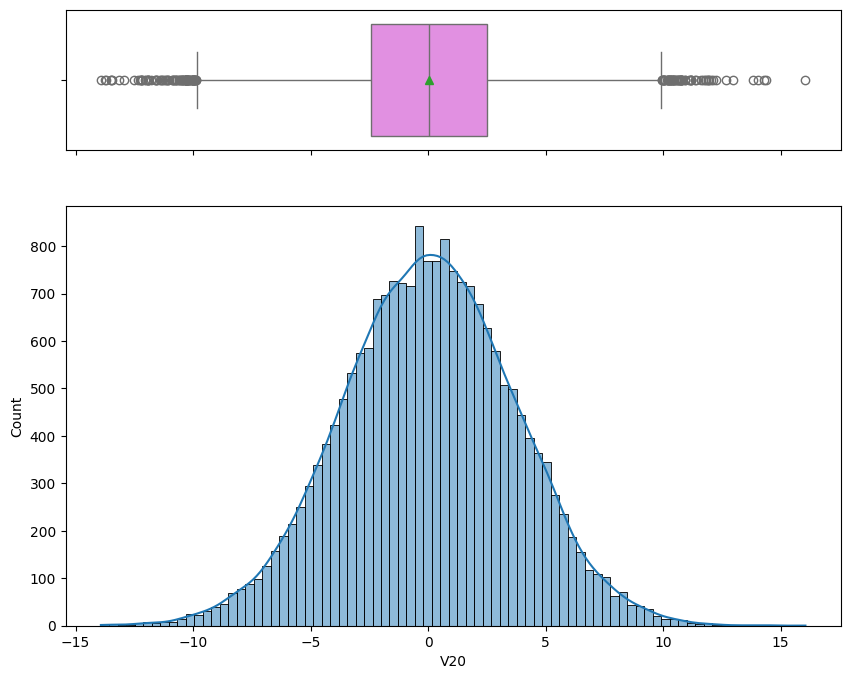

In [ ]:
# Plot histogram and boxplot for 'V20' feature
histogram_boxplot(df, "V20")

#### Observations
V20 shows an approximately symmetric, near-normal distribution centered around 0 with moderate spread and a few outliers on both ends.

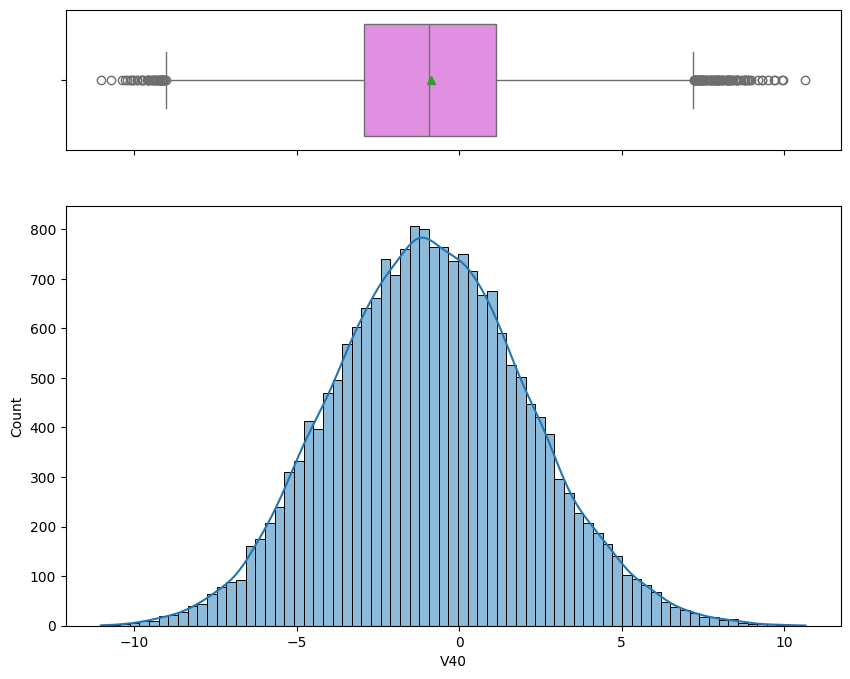

In [ ]:
# Plot histogram and boxplot for 'V40' feature
histogram_boxplot(df, "V40")

#### Observations:
V40 exhibits an approximately normal distribution centered near 0 with moderate variability and a few extreme outliers on both tails.

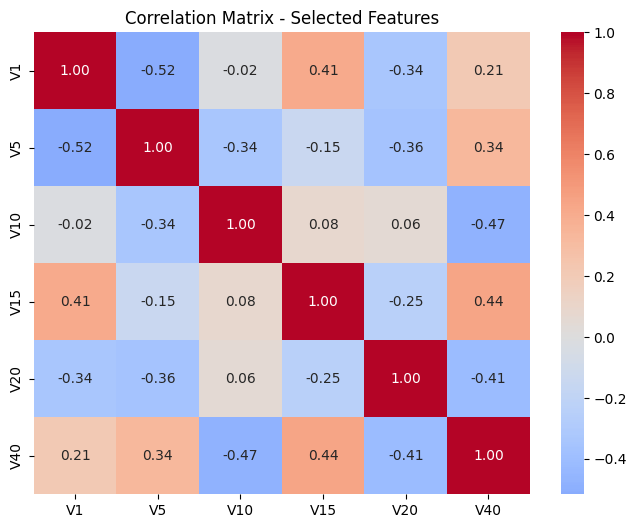

In [ ]:
# Plot a heatmap of correlations between all features
selected_features = ['V1', 'V5', 'V10', 'V15', 'V20', 'V40']
# Create correlation matrix for selected features
corr_selected = df[selected_features].corr()

corr_selected

plt.figure(figsize=(8,6))
sns.heatmap(corr_selected,
            annot=True,
            cmap='coolwarm',
            center=0,
            fmt=".2f")

plt.title("Correlation Matrix - Selected Features")
plt.show()


#### Observations:
The selected features show moderate correlations (both positive and negative) but no extremely high correlation (>0.8), indicating low risk of strong multicollinearity.

### Bivariate Analysis

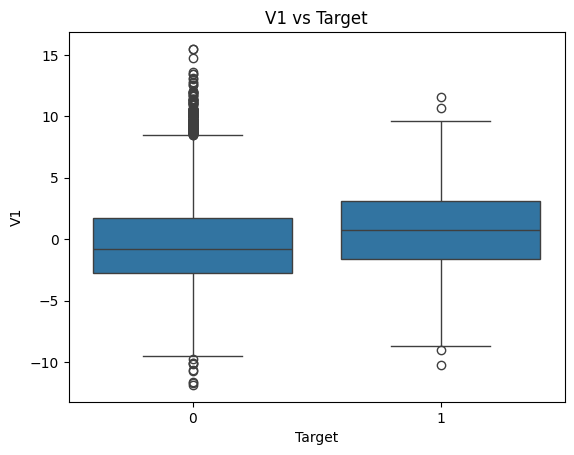

In [ ]:
#Box plot fot Target vs V1
sns.boxplot(x='Target', y='V1', data=df)
plt.title("V1 vs Target")
plt.show()


#### Observations
V1 values are generally higher for failures (1) than for non-failures (0).

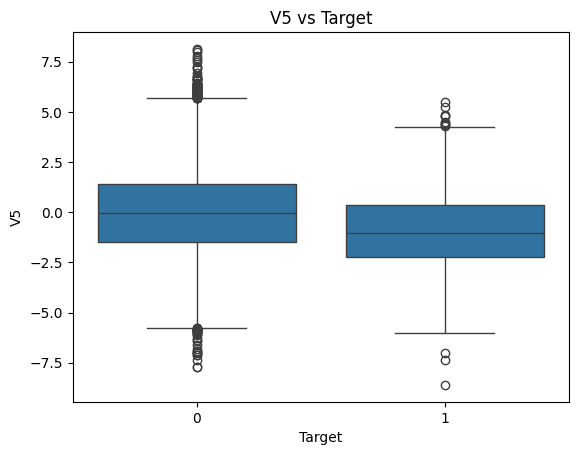

In [ ]:
#Box plot fot Target vs V5
sns.boxplot(x='Target', y='V5', data=df)
plt.title("V5 vs Target")
plt.show()

#### Observations
V5 values are generally lower for failures (1) compared to non-failures (0).

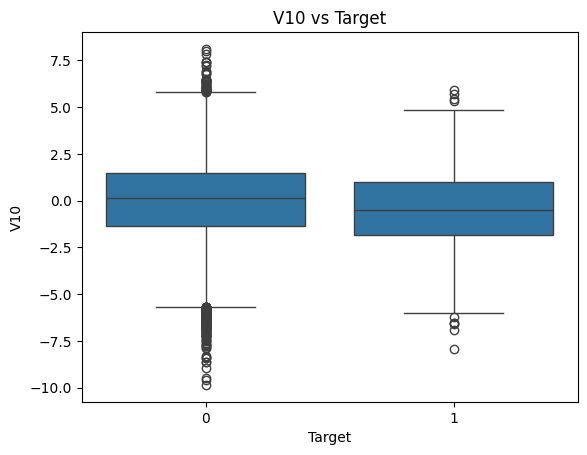

In [ ]:
#Box plot fot Target vs V10
sns.boxplot(x='Target', y='V10', data=df)
plt.title("V10 vs Target")
plt.show()

#### Observations
V10 values are slightly lower for failures (1) compared to non-failures (0), showing a small shift in distribution.

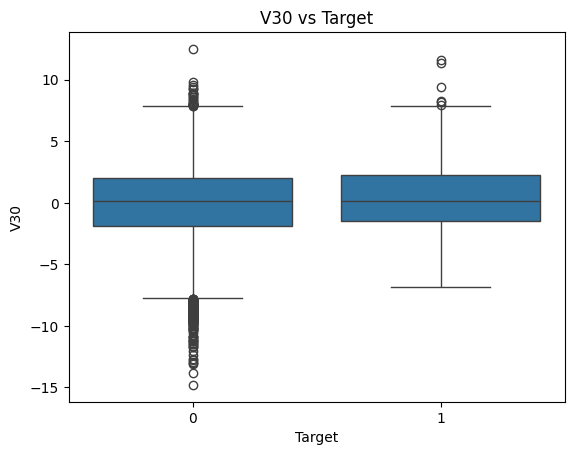

In [ ]:
#Box plot fot Target vs V30
sns.boxplot(x='Target', y='V30', data=df)
plt.title("V30 vs Target")
plt.show()

#### Observations
V30 values are slightly higher for failures (1) than for non-failures (0), indicating a mild positive shift.

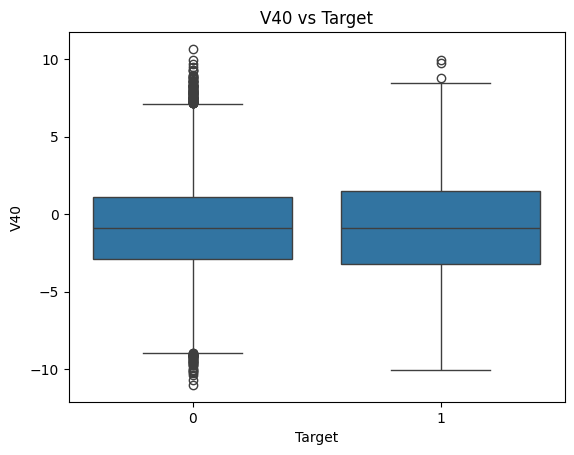

In [ ]:
#Box plot fot Target vs V40
sns.boxplot(x='Target', y='V40', data=df)
plt.title("V40 vs Target")
plt.show()

#### Observations
V40 values are slightly higher for failures (1) compared to non-failures (0), showing a small upward shift in distribution.

## Data Preprocessing

### Handling Missing Values

In [ ]:
# As there are very few missing values , removing them from the train data set wont impact the final predications
df = df.dropna()
df_test = df_test.dropna()

In [ ]:
# Separating Independent and Dependent Columns
X_train = df.drop('Target', axis=1)
y_train = df['Target']


In [ ]:
# Separating Independent and Dependent Columns for test data set
X_test = df_test.drop('Target', axis=1)
y_test = df_test['Target']


In [ ]:
# Standardize features by removing the mean and scaling to unit variance.
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (19964, 40)
Shape of test set :  (4989, 40)
Percentage of classes in training set:
Target
0    0.9444
1    0.0556
Name: proportion, dtype: float64
Percentage of classes in test set:
Target
0    0.943476
1    0.056524
Name: proportion, dtype: float64


### Splitting the dataset

In [ ]:
# Splitting the Train dataset into the Training and Validation set.
X_train, X_valid, y_train, y_valid = train_test_split(X_train,y_train, test_size = 0.2, random_state = 42,stratify = y_train)

In [ ]:
#Printing the shapes.
print(X_train.shape,y_train.shape)
print(X_valid.shape,y_valid.shape)
print(X_test.shape,y_test.shape)

(15971, 40) (15971,)
(3993, 40) (3993,)
(4989, 40) (4989,)


### Utility functions

In [ ]:
def plot(history, name):
    """
    Function to plot loss/accuracy

    history: an object which stores the metrics and losses.
    name: can be one of Loss or Accuracy
    """
    fig, ax = plt.subplots() #Creating a subplot with figure and axes.
    plt.plot(history.history[name]) #Plotting the train accuracy or train loss
    plt.plot(history.history['val_'+name]) #Plotting the validation accuracy or validation loss

    plt.title('Model ' + name.capitalize()) #Defining the title of the plot.
    plt.ylabel(name.capitalize()) #Capitalizing the first letter.
    plt.xlabel('Epoch') #Defining the label for the x-axis.
    fig.legend(['Train', 'Validation'], loc="outside right upper") #Defining the legend, loc controls the position of the legend.

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(
    model, predictors, target, threshold=0.5
):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    threshold: threshold for classifying the observation as class 1
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors) > threshold
    # pred_temp = model.predict(predictors) > threshold
    # # rounding off the above values to get classes
    # pred = np.round(pred_temp)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},
        index=[0],
    )

    return df_perf

###Model Evaluation Criterion

**A model can make wrong predictions in the following ways:**
* False Positive (FP):
  Predicting a generator failure when there is actually no failure.
→ This leads to inspection cost.
* False Negative (FN):
Predicting no failure when the generator is actually going to fail.
→ This leads to replacement cost (very high).

**Which case is more important and how to reduce this loss i.e need to reduce False Negatives as well as False Positives?**

* In the ReneWind predictive maintenance problem, False Negatives are more costly than False Positives because missing a generator failure leads to expensive replacement costs. However, False Positives also result in inspection costs. Therefore, both types of errors need to be minimized.
* The F1-score is selected as the primary evaluation metric as it balances precision and recall. Additionally, class weights will be used to address potential class imbalance and improve failure detection.

In [ ]:
# Calculate class weights for imbalanced dataset
cw = (y_train.shape[0]) / np.bincount(y_train)

# Create a dictionary mapping class indices to their respective class weights
cw_dict = {}
for i in range(cw.shape[0]):
    cw_dict[i] = cw[i]

cw_dict

{0: np.float64(1.058874229264735), 1: np.float64(17.98536036036036)}

In [ ]:
# defining the batch size and # epochs upfront as we'll be using the same values for all models
epochs = 25
batch_size = 64

### Model 0
  Let's start with a neural network consisting of
  * Two hidden layers with 14 and 7 neurons respectively
  * Activation function of ReLU.
  * SGD as the optimizer




In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dense(7,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# SGD as the optimizer to be used
optimizer = tf.keras.optimizers.SGD()
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.2331 - val_loss: 0.4853
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7105 - val_loss: 0.3132
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5699 - val_loss: 0.2544
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5104 - val_loss: 0.2278
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4763 - val_loss: 0.2123
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4521 - val_loss: 0.2007
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4325 - val_loss: 0.1926
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4159 - val_loss: 0.1789
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4024 - val_loss: 0.1742
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3921 - val_loss: 0.1692
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3801 - val_loss: 0.1659
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  20.865514755249023


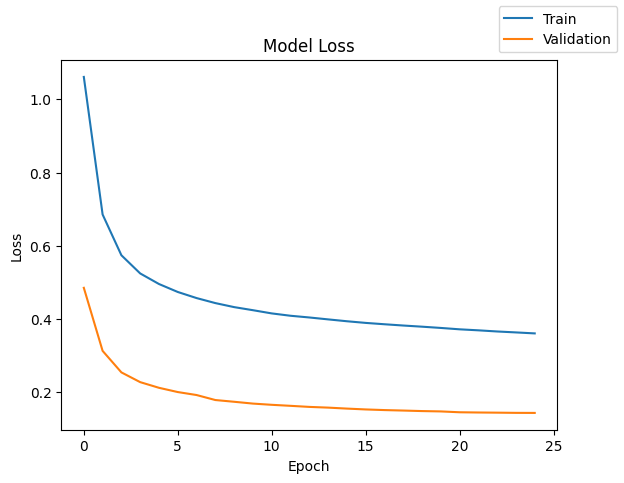

In [ ]:
plot(history,'loss')

In [ ]:
model_0_train_perf = model_performance_classification(model, X_train, y_train)
model_0_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.971887,0.971887,0.977325,0.973685


In [ ]:
model_0_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_0_valid_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.975457,0.975457,0.979425,0.97678


* Train F1 score of ~0.97 and test F1 score of ~0.96 indicate consistent performance of the model between training and testing datasets.

* Even though it's a good score, the rate of improvement over the epochs is still low.

### Model 1
 * After the 7th epoch, the model's rate of learning is low.
  * Let's add momentum to check whether it's accelerating the learning process.




In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dense(7,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# SGD as the optimizer to be used
optimizer = tf.keras.optimizers.SGD(momentum=0.9)
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8452 - val_loss: 0.3275
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4656 - val_loss: 0.2018
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4174 - val_loss: 0.1915
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3903 - val_loss: 0.1664
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3645 - val_loss: 0.1526
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3391 - val_loss: 0.1438
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3321 - val_loss: 0.1478
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3218 - val_loss: 0.1321
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3128 - val_loss: 0.1276
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3140 - val_loss: 0.1357
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3060 - val_loss: 0.1350
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  20.353768587112427


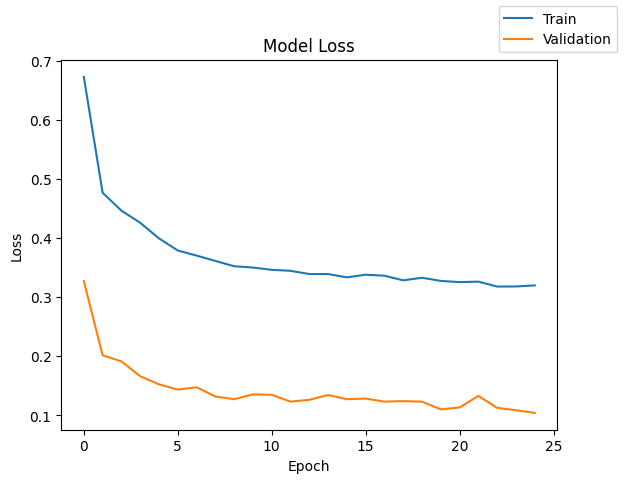

In [ ]:
plot(history,'loss')

In [ ]:
model_1_train_perf = model_performance_classification(model, X_train, y_train)
model_1_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.987352,0.987352,0.98763,0.98747


In [ ]:
model_1_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_1_valid_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.986476,0.986476,0.986664,0.986561


* Train F1 score of ~0.98 and test F1 score of ~0.98 indicate consistent performance of the model between training and testing datasets.
* As expected, there is a improvement in the train scores.

### Model 2
  * Let's change the optimizer to Adam
  * This will introduce momentum as well as an adaptive learning rate




In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dense(7,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Adam as the optimizer to be used
optimizer = tf.keras.optimizers.Adam()
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.9721 - val_loss: 0.3230
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5601 - val_loss: 0.2488
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4859 - val_loss: 0.2178
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4491 - val_loss: 0.2005
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4259 - val_loss: 0.1880
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4101 - val_loss: 0.1795
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3973 - val_loss: 0.1720
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3849 - val_loss: 0.1667
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3752 - val_loss: 0.1602
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3663 - val_loss: 0.1562
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3578 - val_loss: 0.1567
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  21.299994230270386


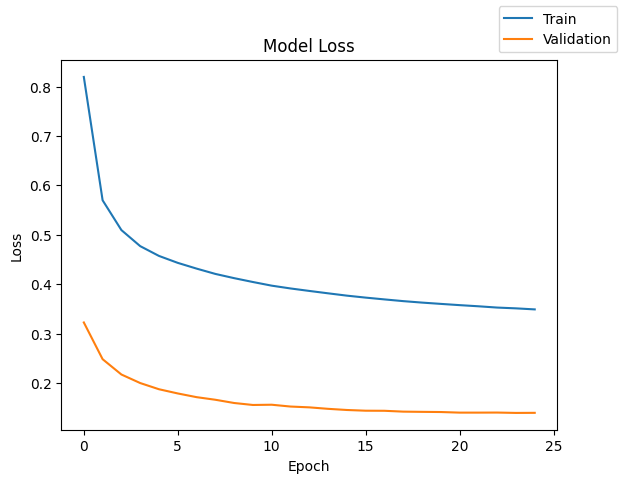

In [ ]:
plot(history,'loss')

In [ ]:
model_2_train_perf = model_performance_classification(model, X_train, y_train)
model_2_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.971824,0.971824,0.977566,0.973697


In [ ]:
model_2_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_2_valid_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.974205,0.974205,0.978886,0.97574


* Train F1 score of ~0.95 and test F1 score of ~0.96 indicate consistent performance of the model between training and testing datasets.


### Model 3
 * Add dropout to regularize it.


In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dropout(0.4))
model.add(Dense(7,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1,activation="sigmoid"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# defining Adam as the optimizer to be used
optimizer = tf.keras.optimizers.Adam()
model.compile(loss='binary_crossentropy', optimizer=optimizer)


In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1.4820 - val_loss: 0.5212
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.0389 - val_loss: 0.4343
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8852 - val_loss: 0.3731
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7943 - val_loss: 0.3157
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7419 - val_loss: 0.2826
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6813 - val_loss: 0.2506
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6838 - val_loss: 0.2432
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6731 - val_loss: 0.2330
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6068 - val_loss: 0.2309
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6001 - val_loss: 0.2246
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5869 - val_loss: 0.2194
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  26.23738694190979


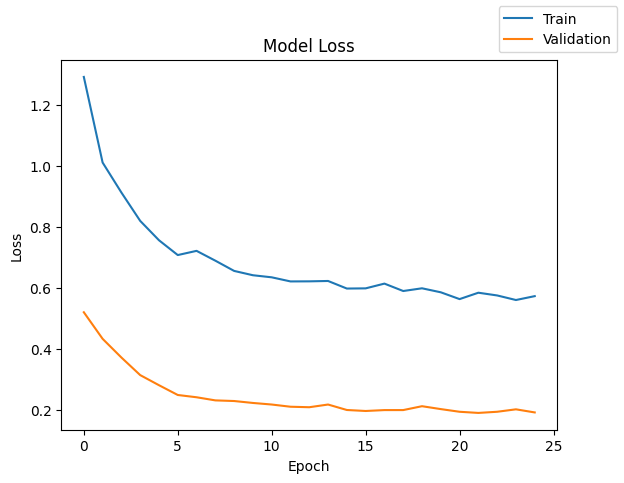

In [ ]:
plot(history,'loss')

In [ ]:
model_3_train_perf = model_performance_classification(model, X_train, y_train)
model_3_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.968005,0.968005,0.97421,0.970137


In [ ]:
model_3_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_3_valid_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.970198,0.970198,0.975663,0.972064


* Train F1 score of ~0.97 and test F1 score of ~0.98 indicate consistent performance of the model.

### Model 4
  * Scores are good but let's add batch normalization to see whether we can stabilize the training process




In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(BatchNormalization())
model.add(Dense(7,activation="relu"))
model.add(BatchNormalization())
model.add(Dense(1,activation="sigmoid"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 14)             │            56 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7)              │            28 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 729 (2.85 KB)

 Non-trainable params: 42 (168.00 B)

In [ ]:
# Adam as the optimizer to be used
optimizer = tf.keras.optimizers.Adam()
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 1.0263 - val_loss: 0.3661
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6114 - val_loss: 0.2264
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4962 - val_loss: 0.1825
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4442 - val_loss: 0.1631
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4155 - val_loss: 0.1588
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3966 - val_loss: 0.1528
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3817 - val_loss: 0.1391
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3713 - val_loss: 0.1394
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3607 - val_loss: 0.1399
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3545 - val_loss: 0.1373
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3497 - val_loss: 0.1345
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  27.15567183494568


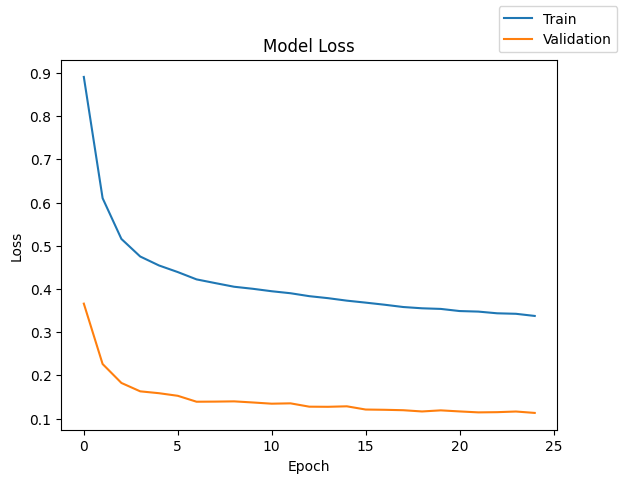

In [ ]:
plot(history,'loss')

In [ ]:
model_4_train_perf = model_performance_classification(model, X_train, y_train)
model_4_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.98228,0.98228,0.983698,0.982793


In [ ]:
model_4_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_4_valid_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.979715,0.979715,0.981771,0.980445


* Train F1 score of ~0.97 and test F1 score of ~0.97 indicate consistent performance of the model between training and testing datasets.

### Model 5
 * Let's add both batchnormalization and dropout.




In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(BatchNormalization())
model.add(Dropout(0.4))
model.add(Dense(7,activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(Dense(1,activation="sigmoid"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 14)             │            56 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7)              │            28 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 729 (2.85 KB)

 Non-trainable params: 42 (168.00 B)

In [ ]:
# Adam as the optimizer to be used
optimizer = tf.keras.optimizers.Adam()
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 1.5621 - val_loss: 0.5622
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0530 - val_loss: 0.4552
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.9145 - val_loss: 0.3737
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8771 - val_loss: 0.3348
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7538 - val_loss: 0.3016
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7439 - val_loss: 0.2853
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7114 - val_loss: 0.2653
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7271 - val_loss: 0.2595
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6869 - val_loss: 0.2559
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6686 - val_loss: 0.2275
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6481 - val_loss: 0.2217
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  26.83668541908264


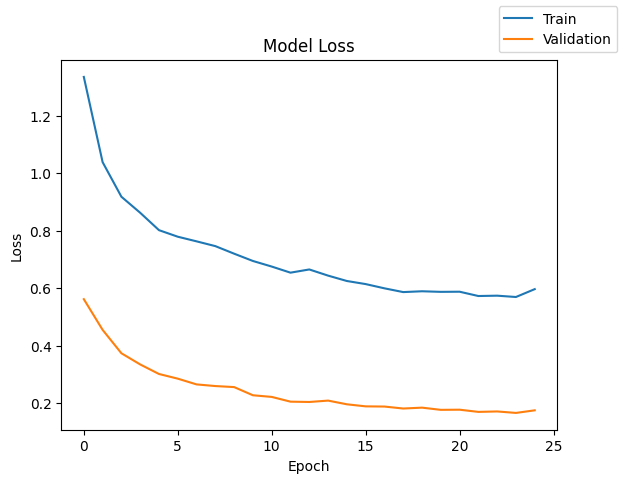

In [ ]:
plot(history,'loss')

In [ ]:
model_5_train_perf = model_performance_classification(model, X_train, y_train)
model_5_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.965813,0.965813,0.973699,0.968451


In [ ]:
model_5_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_5_valid_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.968194,0.968194,0.97582,0.97066


* Train F1 score of ~0.96 and test F1 score of ~0.96 indicate consistent performance of the model between training and testing datasets.

### Model 6
  * Let's initialize the weights using He normal.
  * We'll also use only Dropout for regularization.




In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",kernel_initializer="he_normal",input_dim=X_train.shape[1]))
model.add(Dropout(0.4))
model.add(Dense(7,activation="relu",kernel_initializer="he_normal"))
model.add(Dropout(0.2))
model.add(Dense(1,activation="sigmoid",kernel_initializer="he_normal"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# defining Adam as the optimizer to be used
optimizer = tf.keras.optimizers.Adam()
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1.3814 - val_loss: 0.5830
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0057 - val_loss: 0.4432
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8154 - val_loss: 0.3275
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7276 - val_loss: 0.2981
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6961 - val_loss: 0.2701
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6638 - val_loss: 0.2531
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6416 - val_loss: 0.2436
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6277 - val_loss: 0.2328
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6515 - val_loss: 0.2360
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6236 - val_loss: 0.2220
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6042 - val_loss: 0.2190
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  23.608621835708618


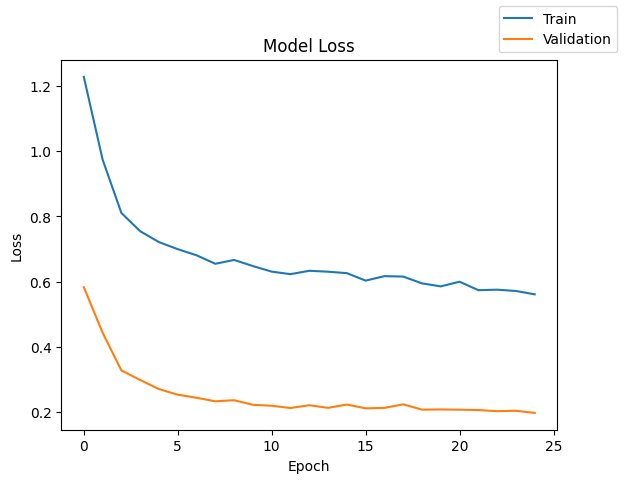

In [ ]:
plot(history,'loss')

In [ ]:
model_6_train_perf = model_performance_classification(model, X_train, y_train)
model_6_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.975643,0.975643,0.978472,0.976665


In [ ]:
model_6_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_6_valid_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.978713,0.978713,0.9807,0.979441


* Train F1 score of ~0.97 and test F1 score of ~0.96 indicate consistent performance of the model between training and testing datasets.

* Even though it's a good score, the rate of improvement over the epochs is still low.

## Model Performance Comparison and Final Model Selection

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        model_0_train_perf.T,
        model_1_train_perf.T,
        model_2_train_perf.T,
        model_3_train_perf.T,
        model_4_train_perf.T,
        model_5_train_perf.T,
        model_6_train_perf.T
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Neural Network (SGD, No Regularization)",
    "Neural Network (SGD with Momentum, No Regularization)",
    "Neural Network (Adam , No Regularization)",
    "Neural Network (Adam, dropout [0.4,0.2])",
    "Neural Network (Adam, Batch Normalization)",
    "Neural Network (dropout [0.4,0.2], Batch Normalization)",
    "Neural Network (Adam,dropout [0.4,0.2] ,He initialization)"
]

In [ ]:
#Validation performance comparison

models_valid_comp_df = pd.concat(
    [
        model_0_valid_perf.T,
        model_1_valid_perf.T,
        model_2_valid_perf.T,
        model_3_valid_perf.T,
        model_4_valid_perf.T,
        model_5_valid_perf.T,
        model_6_valid_perf.T
    ],
    axis=1,
)
models_valid_comp_df.columns = [
    "Neural Network (SGD, No Regularization)",
    "Neural Network (SGD with Momentum, No Regularization)",
    "Neural Network (Adam , No Regularization)",
    "Neural Network (Adam, dropout [0.4,0.2])",
    "Neural Network (Adam, Batch Normalization)",
    "Neural Network (dropout [0.4,0.2], Batch Normalization)",
    "Neural Network (Adam,dropout [0.4,0.2] ,He initialization)"
]

In [ ]:
models_train_comp_df

,"Neural Network (SGD, No Regularization)","Neural Network (SGD with Momentum, No Regularization)","Neural Network (Adam , No Regularization)","Neural Network (Adam, dropout [0.4,0.2])","Neural Network (Adam, Batch Normalization)","Neural Network (dropout [0.4,0.2], Batch Normalization)","Neural Network (Adam,dropout [0.4,0.2] ,He initialization)"
Accuracy,0.971887,0.987352,0.971824,0.968005,0.982280,0.965813,0.975643
Recall,0.971887,0.987352,0.971824,0.968005,0.982280,0.965813,0.975643
Precision,0.977325,0.987630,0.977566,0.974210,0.983698,0.973699,0.978472
F1 Score,0.973685,0.987470,0.973697,0.970137,0.982793,0.968451,0.976665


In [ ]:
models_valid_comp_df


,"Neural Network (SGD, No Regularization)","Neural Network (SGD with Momentum, No Regularization)","Neural Network (Adam , No Regularization)","Neural Network (Adam, dropout [0.4,0.2])","Neural Network (Adam, Batch Normalization)","Neural Network (dropout [0.4,0.2], Batch Normalization)","Neural Network (Adam,dropout [0.4,0.2] ,He initialization)"
Accuracy,0.975457,0.986476,0.974205,0.970198,0.979715,0.968194,0.978713
Recall,0.975457,0.986476,0.974205,0.970198,0.979715,0.968194,0.978713
Precision,0.979425,0.986664,0.978886,0.975663,0.981771,0.975820,0.980700
F1 Score,0.976780,0.986561,0.975740,0.972064,0.980445,0.970660,0.979441


In [ ]:
models_train_comp_df.loc["F1 Score"] - models_valid_comp_df.loc["F1 Score"]


,F1 Score
"Neural Network (SGD, No Regularization)",-0.003094
"Neural Network (SGD with Momentum, No Regularization)",0.000909
"Neural Network (Adam , No Regularization)",-0.002043
"Neural Network (Adam, dropout [0.4,0.2])",-0.001927
"Neural Network (Adam, Batch Normalization)",0.002349
"Neural Network (dropout [0.4,0.2], Batch Normalization)",-0.002209
"Neural Network (Adam,dropout [0.4,0.2] ,He initialization)",-0.002776


**Final Model:** `Neural Network (SGD with Momentum, No Regularization)	`

**Reasoning**:
  * Best F1 score on the training set (~0.98), indicating strong performance in learning from the training data.
  * Best F1 score on the validation set (~0.98), demonstrating good performance in generalizing to unseen data.
  * When considering validation scores only, Model 1 outperforms others, suggesting its effectiveness in real-world applications and new data scenarios.

## Final Model

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dense(7,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
 # defining SGD as the optimizer to be used
optimizer = tf.keras.optimizers.SGD(momentum=0.9)
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.8147 - val_loss: 0.2890
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4696 - val_loss: 0.2705
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4090 - val_loss: 0.2416
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3753 - val_loss: 0.2095
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3681 - val_loss: 0.1757
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3497 - val_loss: 0.1679
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3452 - val_loss: 0.1631
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3329 - val_loss: 0.1555
Epoch 9/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3223 - val_loss: 0.1642
Epoch 10/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3097 - val_loss: 0.1391
Epoch 11/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3066 - val_loss: 0.1333
Epoch 12/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [ ]:
y_train_pred = model.predict(X_train)
y_valid_pred = model.predict(X_valid)
y_test_pred = model.predict(X_test)

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [ ]:
print("Classification Report - Train data",end="\n\n")
cr = classification_report(y_train,y_train_pred>0.5)
print(cr)

Classification Report - Train data

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     15083
           1       0.73      0.92      0.82       888

    accuracy                           0.98     15971
   macro avg       0.86      0.95      0.90     15971
weighted avg       0.98      0.98      0.98     15971



In [ ]:
print("Classification Report - Validation data",end="\n\n")
cr = classification_report(y_valid,y_valid_pred>0.5)
print(cr)

Classification Report - Validation data

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3771
           1       0.72      0.91      0.81       222

    accuracy                           0.98      3993
   macro avg       0.86      0.94      0.90      3993
weighted avg       0.98      0.98      0.98      3993



In [ ]:
print("Classification Report - Test data",end="\n\n")
cr = classification_report(y_test,y_test_pred>0.5)
print(cr)

Classification Report - Test data

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      4707
           1       0.73      0.88      0.79       282

    accuracy                           0.97      4989
   macro avg       0.86      0.93      0.89      4989
weighted avg       0.98      0.97      0.98      4989



* The weighted F1 score on the test data is ~0.98.

* An F1 score of ~0.98 indicates an excellent balance between precision and recall overall, suggesting very strong performance in accurately classifying instances with minimal false positives and false negatives.

* Since the dataset is imbalanced (minority class support = 282 vs 4707), the model can be further tuned to improve performance specifically for the minority class (Class 1), even though overall performance is already strong

## Business Insights and Recommendations
  * The Operations and Maintenance (O&M) team can deploy this model to accurately predict whether a turbine is likely to fail or operate normally.
  This automated system is faster and more cost-efficient than traditional reactive maintenance methods.
  * The company should adopt predictive maintenance strategies based on model outputs to reduce unexpected breakdowns.Detecting 87% of failure cases enables proactive repairs and minimizes revenue loss due to downtime.
  * Turbines can be categorized into low-, medium-, and high-risk groups based on predicted probabilities.This risk-based approach improves maintenance planning and optimizes workforce allocation.
  * Greater focus should be placed on reducing missed failures (false negatives), as they have higher financial impact.
  * Adjusting the classification threshold to increase recall can strengthen preventive maintenance effectiveness and a slight increase in false alarms is acceptable compared to unexpected breakdown costs.
  * Continuous monitoring and feature enhancement will further increase long-term operational reliability.
  Techniques like threshold tuning, oversampling minority failure cases, or using SMOTE can address class imbalance.
  * Regular evaluation using recall and F1-score ensures balanced and stable real-world model performance

## Conclusion
The model demonstrates strong predictive performance with excellent overall accuracy and solid minority class detection. It is suitable for deployment, but further tuning can be applied depending on business cost sensitivity between false positives and false negatives.

[NbConvertApp] Converting notebook /content/Neural_Networks_Project.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 18 image(s).
[NbConvertApp] Writing 1301299 bytes to /content/Neural_Networks_Project.html
